# 02 · Well correlation

The correlate stage aligns all wells to a shared relative-geologic-time axis (`layer_time`) by dynamic time
warping ([Sakoe & Chiba 1978](https://doi.org/10.1109/TASSP.1978.1163055)) between neighboring wells, solved
jointly in the spirit of [Wheeler & Hale (2014)](https://doi.org/10.1190/segam2014-0227.1), with formation
tops as anchors. Run notebook 01 first.

## Setup
Set `SX_EXAMPLE_PROJECT` to your KGS project folder (default `kgs_project/` next to this notebook).

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Load the stage outputs

In [2]:
wells = pq.read_table(PROJ / "export/wells.parquet").to_pandas()
tops = pq.read_table(PROJ / "export/tops.parquet").to_pandas()
lt = pq.read_table(PROJ / "export/layer_time.parquet").to_pandas()
geo = pq.read_table(PROJ / "export/geometry.parquet").to_pandas()
fin = pq.read_table(PROJ / "export/logs_final.parquet", columns=["well_id", "k", "gr_api"]).to_pandas()
print(len(wells), "wells;", int(tops.suspect.sum()), "of", len(tops), "tops flagged suspect")
tops.groupby("top_name").agg(n=("md_ft", "size"), suspect=("suspect", "sum"), mean_elev_ft=("elev_ft", "mean")).sort_values("mean_elev_ft", ascending=False)

60 wells; 16 of 960 tops flagged suspect


,n,suspect,mean_elev_ft
top_name,,,
Heebner,60,0,-2299.568966
Douglas,60,0,-2340.558333
Stark,60,0,-2992.133929
Hushpuckney,60,0,-3025.790698
Hertha,60,1,-3026.833333
Pawnee,60,1,-3160.767241
Cherokee,60,2,-3197.160714
Cherokee Sand,60,1,-3241.333333
Mississippian,60,2,-3248.305085


## West–east section
Eight wells from west to east, GR curves (black) between 3,000 and 3,700 ft below sea level, with the KGS formation
tops named in the legend. Right: the same curves on `layer_time`, the relative geological time from the
correlation: each top is an anchor (`layer_time` = top number + 1) and the DTW alignment fills in between, so this
is a Wheeler-style (chronostratigraphic) view in which correlated beds line up. Left: the same correlation on depth;
each colour band joins one `layer_time` interval (0.25 wide) between neighbouring wells, coloured by the mean GR of
that interval over the eight wells.

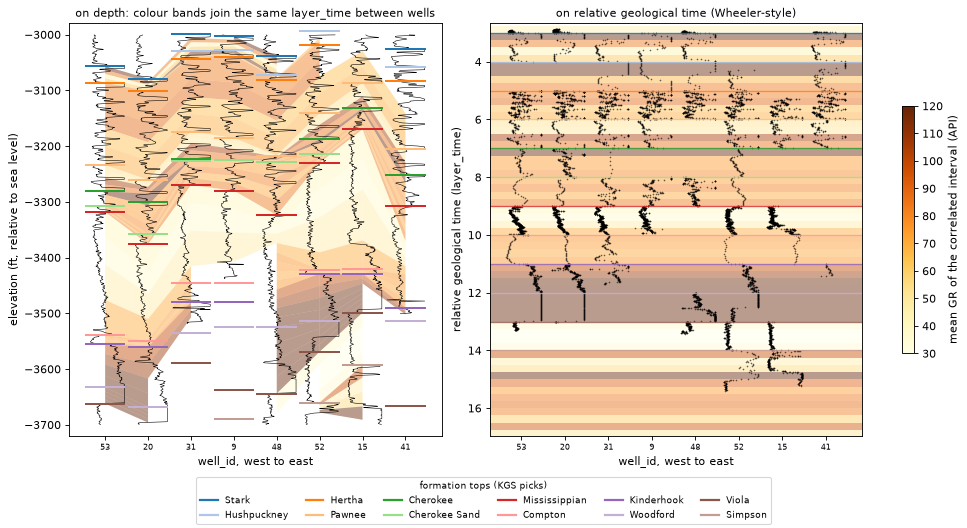

In [3]:
sel = wells.sort_values("x_m").iloc[:: max(1, len(wells) // 8)].head(8)
d = fin.merge(lt, on=["well_id", "k"]).merge(geo[["well_id", "k", "elev_ft"]], on=["well_id", "k"])
d = d[(d.elev_ft < -3000) & (d.elev_ft > -3700)]
names = tops.groupby("top_name").agg(e=("elev_ft", "mean"), t=("top_index", "first")).sort_values("e", ascending=False)
names = names[(names.e < -2990) & (names.e > -3700)]                     # tops inside the window
tcol = dict(zip(names.index, plt.cm.tab20(np.arange(len(names)) % 20)))
levels = np.arange(np.floor(d.layer_time.min()), np.ceil(d.layer_time.max()) + 1e-9, 0.25)
gr_band = d.groupby(np.digitize(d.layer_time, levels)).gr_api.mean()         # mean GR of each correlated interval
norm = plt.Normalize(30, 120); band_cmap = plt.get_cmap("managua")
def elev_at(s, lv):                                                     # depth of a layer_time level in one well
    s = s.dropna(subset=["layer_time"]).sort_values("layer_time")
    return np.interp(lv, s.layer_time, s.elev_ft, left=np.nan, right=np.nan)
fig, axs = plt.subplots(1, 2, figsize=(12, 6.5), layout="constrained")
per = [d[d.well_id == w] for w in sel.well_id]
for i in range(len(per) - 1):                                            # correlated intervals between neighbours
    ea, eb = elev_at(per[i], levels), elev_at(per[i + 1], levels)
    for m in range(len(levels) - 1):
        q = [ea[m], eb[m], eb[m + 1], ea[m + 1]]
        if np.all(np.isfinite(q)) and (m + 1) in gr_band.index:
            axs[0].fill([i + 0.45, i + 1.45, i + 1.45, i + 0.45], q, color=band_cmap(norm(gr_band[m + 1])), alpha=0.35, lw=0)
for i, s in enumerate(per):
    g = (s.gr_api.clip(0, 150) / 150) * 0.9 + i
    axs[0].plot(g, s.elev_ft, lw=0.5, color="k"); axs[1].plot(g, s.layer_time, ".", ms=0.6, color="k")
    for _, row in tops[(tops.well_id == s.well_id.iloc[0]) & tops.top_name.isin(list(tcol))].iterrows():
        axs[0].plot([i, i + 0.9], [row.elev_ft] * 2, color=tcol[row.top_name], lw=1.8)
for n, r in names.iterrows():                                            # tops are the anchors: layer_time = index + 1
    axs[1].axhline(r.t + 1, color=tcol[n], lw=1.2, alpha=0.8)
for m in range(len(levels) - 1):
    if (m + 1) in gr_band.index:
        axs[1].axhspan(levels[m], levels[m + 1], color=band_cmap(norm(gr_band[m + 1])), alpha=0.35, lw=0, zorder=0)
axs[0].set_ylabel("elevation (ft, relative to sea level)"); axs[1].set_ylabel("relative geological time (layer_time)")
axs[0].set_ylim(-3720, -2980); axs[1].set_ylim(d.layer_time.max() + 0.2, d.layer_time.min() - 0.2)
for ax, t in zip(axs, ["on depth: colour bands join the same layer_time between wells", "on relative geological time (Wheeler-style)"]):
    ax.set_title(t, fontsize=10); ax.set_xticks(np.arange(len(sel)) + 0.45); ax.set_xticklabels(sel.well_id, fontsize=7)
    ax.set_xlabel("well_id, west to east")
fig.legend([plt.Line2D([], [], color=tcol[n], lw=2) for n in names.index], list(names.index), loc="outside lower center",
           ncol=min(len(names), 6), fontsize=8, title="formation tops (KGS picks)", title_fontsize=8)
fig.colorbar(plt.cm.ScalarMappable(norm, band_cmap), ax=axs, shrink=0.6, label="mean GR of the correlated interval (API)")
save(fig, "02_correlation_section.png")

## Top consistency
Spread of each top among neighboring wells after correlation; large spreads point to tops worth checking.

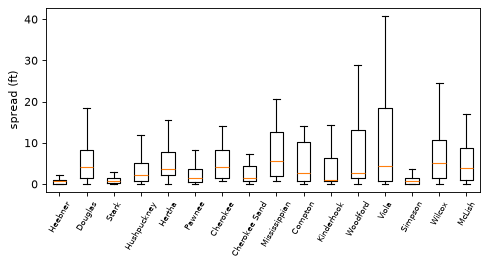

In [4]:
order = tops.groupby("top_name").elev_ft.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([tops[tops.top_name == n].spread_ft.dropna() for n in order], tick_labels=list(order), showfliers=False)
ax.set_ylabel("spread (ft)"); ax.tick_params(axis="x", rotation=60, labelsize=7)
save(fig, "02_top_spread.png")

The same workflow runs on the FORCE 2020 North Sea wells ([Bormann et al. 2020](https://doi.org/10.5281/zenodo.4351155)):
fetch them with `scripts/fetch_force2020.sh`, convert with `force2020_to_las.py`, and use `force2020_project.toml`.